# Evolutionary Design Optimization of an Aircraft Configuration

A multi-objective optimization problem for the conceptual design of an aircraft using evolutionary algorithms. The aim is to generate aircraft configurations that reduce aerodynamic drag, provide sufficient fuel volume inside the wings, and maximize cargo capacity.

## 1. Problem Statement

The objective is to design an aircraft configuration using evolutionary algorithms. Each candidate solution represents a possible aircraft geometry described by a vector of design variables.

The aircraft should be optimized with respect to three main criteria:

1. Minimize aerodynamic drag.
2. Maximize the available fuel volume inside the wings.
3. Maximize the available cargo space.

These criteria are conflicting. For example, reducing drag may require thinner wings, but thinner wings reduce the internal fuel volume. Increasing cargo capacity may require a larger fuselage, but a larger fuselage may increase drag. The optimizer must therefore search for compromise solutions rather than a single perfect solution.

## 2. Design Variable Vector

Let the aircraft design be represented by the vector:

$$
x = \left[ b, S_w, AR, \Lambda, t_c, L_f, D_f, V_c, V_f, S_t, x_e \right]
$$

where:

- $b$ is the wing span;
- $S_w$ is the wing area;
- $AR$ is the wing aspect ratio;
- $\Lambda$ is the wing sweep angle;
- $t_c$ is the wing thickness-to-chord ratio;
- $L_f$ is the fuselage length;
- $D_f$ is the fuselage diameter;
- $V_c$ is the available cargo volume;
- $V_f$ is the fuel volume stored inside the wings;
- $S_t$ is the tail surface area;
- $x_e$ is the engine placement variable.

A simplified relation for the aspect ratio is:

$$
AR = \frac{b^2}{S_w}
$$

This relation can either be imposed as a constraint or used to compute $AR$ directly from $b$ and $S_w$.

## 3. Objective Functions

The aircraft design problem is formulated as a multi-objective optimization problem.

The first objective is to minimize the drag coefficient:

$$
\min f_1(x) = C_D(x)
$$

The second objective is to maximize the fuel volume inside the wings:

$$
\max f_2(x) = V_{fuel}(x)
$$

The third objective is to maximize the available cargo volume:

$$
\max f_3(x) = V_{cargo}(x)
$$

Since many evolutionary algorithms are formulated as minimization algorithms, the problem can be written as:

$$
\min F(x) = \left[ C_D(x), -V_{fuel}(x), -V_{cargo}(x) \right]
$$

where:

- $C_D(x)$ is the aerodynamic drag coefficient;
- $V_{fuel}(x)$ is the fuel volume stored inside the wings;
- $V_{cargo}(x)$ is the available cargo space.

## 4. Simplified Aerodynamic Model

A simplified drag model may be used during conceptual design:

$$
C_D(x) = C_{D0}(x) + C_{Di}(x)
$$

where $C_{D0}(x)$ is the zero-lift drag coefficient and $C_{Di}(x)$ is the induced drag coefficient.

The induced drag coefficient may be approximated as:

$$
C_{Di}(x) = \frac{C_L^2}{\pi e AR}
$$

where $C_L$ is the lift coefficient, $e$ is the Oswald efficiency factor, and $AR$ is the wing aspect ratio.

The lift coefficient can be approximated by:

$$
C_L = \frac{2W}{\rho V^2 S_w}
$$

where $W$ is the aircraft weight, $\rho$ is the air density, $V$ is the flight velocity, and $S_w$ is the wing area.

The drag force may be estimated as:

$$
D(x) = \frac{1}{2}\rho V^2 S_w C_D(x)
$$

## 5. Fuel Volume Model

The fuel volume stored in the wings depends on the wing geometry and the internal usable volume. A simplified approximation is:

$$
V_{fuel}(x) = k_f S_w \bar{c} t_c
$$

where $k_f$ is a fuel-volume efficiency coefficient, $S_w$ is the wing area, $\bar{c}$ is the mean aerodynamic chord, and $t_c$ is the wing thickness-to-chord ratio.

The mean aerodynamic chord may be approximated as:

$$
\bar{c} = \frac{S_w}{b}
$$

Therefore:

$$
V_{fuel}(x) = k_f S_w \left( \frac{S_w}{b} \right) t_c
$$

## 6. Cargo Volume Model

The cargo volume is mainly influenced by the fuselage geometry. A simplified model is:

$$
V_{cargo}(x) = k_c L_f D_f^2
$$

where $k_c$ is a cargo-space efficiency coefficient, $L_f$ is the fuselage length, and $D_f$ is the fuselage diameter.

A larger fuselage may increase cargo space, but it may also increase aerodynamic drag and structural weight.

## 7. Constraints

The aircraft design must satisfy aerodynamic, structural, stability, and capacity constraints.

### 7.1 Lift Constraint

The generated lift must be at least equal to the aircraft weight:

$$
L(x) \geq W(x)
$$

where:

$$
L(x) = \frac{1}{2}\rho V^2 S_w C_L
$$

### 7.2 Minimum Fuel Capacity

$$
V_{fuel}(x) \geq V_{fuel}^{min}
$$

### 7.3 Minimum Cargo Capacity

$$
V_{cargo}(x) \geq V_{cargo}^{min}
$$

### 7.4 Structural Constraint

$$
\sigma(x) \leq \sigma_{max}
$$

### 7.5 Wing Area Bounds

$$
S_w^{min} \leq S_w(x) \leq S_w^{max}
$$

### 7.6 Aspect Ratio Bounds

$$
AR^{min} \leq AR(x) \leq AR^{max}
$$

### 7.7 Stability Constraint

$$
SM(x) \geq SM_{min}
$$

where $SM(x)$ is the static margin.

## 8. Evolutionary Algorithm Formulation

An evolutionary algorithm can be used to solve this constrained multi-objective problem. Suitable algorithms include Genetic Algorithm, NSGA-II, Differential Evolution, Multi-Objective Particle Swarm Optimization, and Evolution Strategies.

Each individual in the population represents an aircraft design:

$$
P = \{x_1, x_2, \ldots, x_N\}
$$

where $N$ is the population size.

Each individual is evaluated using the objective vector:

$$
F(x_i) = \left[ C_D(x_i), -V_{fuel}(x_i), -V_{cargo}(x_i) \right]
$$

The evolutionary algorithm applies selection, crossover, mutation, and replacement operators in order to evolve better aircraft designs over multiple generations.

## 9. Constraint Handling

Constraints can be handled using a penalty function. The penalized objective can be written as:

$$
F_p(x) = F(x) + \lambda P(x)
$$

where $F_p(x)$ is the penalized objective vector, $F(x)$ is the original objective vector, $\lambda$ is a penalty coefficient, and $P(x)$ is the total constraint violation.

A possible total penalty function is:

$$
P(x) = \sum_{j=1}^{m} \max(0, g_j(x))^2
$$

where $g_j(x) \leq 0$ represents the $j$-th inequality constraint.

## 10. Pareto Optimality

Because the problem has multiple conflicting objectives, the final output should not be a single design, but a set of Pareto-optimal aircraft configurations.

A design $x_a$ dominates another design $x_b$ if:

$$
f_i(x_a) \leq f_i(x_b), \quad \forall i
$$

and:

$$
\exists j \text{ such that } f_j(x_a) < f_j(x_b)
$$

The set of non-dominated solutions forms the Pareto front:

$$
PF = \{x \in X \mid \nexists y \in X : y \prec x\}
$$

where $y \prec x$ means that $y$ dominates $x$.

### Explanation of Pareto optimality

In a multi-objective optimization problem, several objectives must be optimized at the same time. 
Since these objectives may conflict with each other, there is usually no single solution that is optimal 
for all objectives simultaneously.

Let a solution be represented by a vector of decision variables:

$$\mathbf{x} = (x_1, x_2, \ldots, x_n) \in \Omega,$$


where $\Omega$ is the feasible search space. The objective function is defined as:

$$\mathbf{f}(\mathbf{x}) = \left(f_1(\mathbf{x}), f_2(\mathbf{x}), \ldots, f_m(\mathbf{x})\right),$$


where $m$ is the number of objectives.

Assuming a minimization problem, a solution $\mathbf{x}^{(1)}$ is said to dominate another solution 
$\mathbf{x}^{(2)}$, written as:

$$\mathbf{x}^{(1)} \prec \mathbf{x}^{(2)},$$

if the following two conditions are satisfied:

$$f_i(\mathbf{x}^{(1)}) \leq f_i(\mathbf{x}^{(2)}), \quad \forall i \in \{1,2,\ldots,m\},$$


and

$$\exists j \in \{1,2,\ldots,m\} \text{ such that } f_j(\mathbf{x}^{(1)}) < f_j(\mathbf{x}^{(2)}).$$


In other words, $\mathbf{x}^{(1)}$ is at least as good as $\mathbf{x}^{(2)}$ in all objectives and strictly 
better in at least one objective.

A solution $\mathbf{x}^*$ is called Pareto optimal if there is no other feasible solution 
$\mathbf{x} \in \Omega$ that dominates it:

$$\nexists \mathbf{x} \in \Omega \text{ such that } \mathbf{x} \prec \mathbf{x}^*.$$


The set of all Pareto optimal solutions is called the Pareto set:

$$P^* = \left\{ \mathbf{x}^* \in \Omega \mid \nexists \mathbf{x} \in \Omega : \mathbf{x} \prec \mathbf{x}^* \right\}.$$


The image of the Pareto set in the objective space is called the Pareto front:

$$PF^* = \left\{ \mathbf{f}(\mathbf{x}^*) \mid \mathbf{x}^* \in P^* \right\}.$$

In the aircraft design problem, the Pareto front contains aircraft designs that represent different 
trade-offs between objectives such as minimizing drag, minimizing fuel volume in the wings, and 
maximizing cargo space. A design on the Pareto front cannot be improved in one objective without 
worsening at least one other objective.

## 11. Generic Evolutionary Algorithm Procedure

The evolutionary optimization process can be summarized as follows:

1. Initialize a population of aircraft designs.
2. Evaluate aerodynamic drag, fuel volume, and cargo volume for each design.
3. Check constraints and apply penalties if necessary.
4. Select the best individuals based on Pareto dominance and diversity.
5. Apply crossover to generate new aircraft designs.
6. Apply mutation to introduce geometric variation.
7. Replace part or all of the population with the new individuals.
8. Repeat the process until a stopping criterion is met.
9. Return the Pareto-optimal set of aircraft designs.

The stopping criterion may be:

$$
t \geq T_{max}
$$

or:

$$
\Delta PF \leq \varepsilon
$$

where $t$ is the current generation, $T_{max}$ is the maximum number of generations, $\Delta PF$ is the change in the Pareto front, and $\varepsilon$ is a convergence threshold.

## 12. Example Python Skeleton

The following code provides a minimal structure for evaluating candidate aircraft designs. This is not a full aerodynamic solver. It is a simplified conceptual model intended for optimization experiments.

In [1]:
import numpy as np

# Constants used in the simplified model
rho = 1.225          # air density at sea level [kg/m^3]
V = 230.0            # cruise speed [m/s]
e = 0.8              # Oswald efficiency factor
W = 7.0e5            # aircraft weight [N]
k_f = 0.45           # fuel volume efficiency coefficient
k_c = 0.60           # cargo volume efficiency coefficient

# Minimum requirements
V_fuel_min = 80.0    # minimum fuel volume [m^3]
V_cargo_min = 120.0  # minimum cargo volume [m^3]
AR_min = 6.0
AR_max = 14.0
S_w_min = 80.0
S_w_max = 300.0

In [2]:
def evaluate_aircraft(x):
    """
    Evaluate a simplified aircraft design.
    Design vector: x = [b, S_w, sweep, t_c, L_f, D_f]
    """
    b, S_w, sweep, t_c, L_f, D_f = x
    AR = b**2 / S_w
    C_L = 2 * W / (rho * V**2 * S_w)
    C_D0 = 0.018 + 0.002 * (D_f / L_f) + 0.0001 * abs(sweep)
    C_Di = C_L**2 / (np.pi * e * AR)
    C_D = C_D0 + C_Di
    c_bar = S_w / b
    V_fuel = k_f * S_w * c_bar * t_c
    V_cargo = k_c * L_f * D_f**2
    return C_D, V_fuel, V_cargo, AR

In [3]:
def constraint_penalty(x):
    """Compute a simple penalty for constraint violations."""
    C_D, V_fuel, V_cargo, AR = evaluate_aircraft(x)
    b, S_w, sweep, t_c, L_f, D_f = x
    violations = [
        max(0, V_fuel_min - V_fuel),
        max(0, V_cargo_min - V_cargo),
        max(0, AR_min - AR),
        max(0, AR - AR_max),
        max(0, S_w_min - S_w),
        max(0, S_w - S_w_max),
    ]
    return sum(v**2 for v in violations)

In [4]:
def objective_function(x, penalty_weight=1e3):
    """
    Multi-objective function converted into a penalized vector.
    Objectives: minimize drag, maximize fuel volume, maximize cargo volume.
    """
    C_D, V_fuel, V_cargo, AR = evaluate_aircraft(x)
    penalty = constraint_penalty(x)
    return np.array([
        C_D + penalty_weight * penalty,
        -V_fuel + penalty_weight * penalty,
        -V_cargo + penalty_weight * penalty,
    ])

In [5]:
# Example candidate aircraft design
# x = [wing span, wing area, sweep angle, thickness-to-chord ratio, fuselage length, fuselage diameter]
x_example = np.array([42.0, 140.0, 25.0, 0.12, 38.0, 4.5])

C_D, V_fuel, V_cargo, AR = evaluate_aircraft(x_example)
F = objective_function(x_example)

print("Example aircraft design:")
print(f"Drag coefficient C_D: {C_D:.5f}")
print(f"Fuel volume: {V_fuel:.2f} m^3")
print(f"Cargo volume: {V_cargo:.2f} m^3")
print(f"Aspect ratio: {AR:.2f}")
print(f"Objective vector: {F}")

Example aircraft design:
Drag coefficient C_D: 0.02149
Fuel volume: 25.20 m^3
Cargo volume: 461.70 m^3
Aspect ratio: 12.60
Objective vector: [3003040.02148882 3003014.8        3002578.3       ]


## 13. Final Problem Formulation

The complete problem can be stated as follows:

Design an aircraft configuration using evolutionary algorithms in order to minimize aerodynamic drag, maximize the fuel volume stored in the wings, and maximize the available cargo space. The problem is treated as a constrained multi-objective optimization task, where each candidate solution represents a complete aircraft geometry.

The final optimization problem is:

$$
\min F(x) = \left[ C_D(x), -V_{fuel}(x), -V_{cargo}(x) \right]
$$

subject to:

$$
L(x) \geq W(x)
$$

$$
V_{fuel}(x) \geq V_{fuel}^{min}
$$

$$
V_{cargo}(x) \geq V_{cargo}^{min}
$$

$$
\sigma(x) \leq \sigma_{max}
$$

$$
S_w^{min} \leq S_w(x) \leq S_w^{max}
$$

$$
AR^{min} \leq AR(x) \leq AR^{max}
$$

$$
SM(x) \geq SM_{min}
$$

The evolutionary algorithm should return a Pareto front of feasible aircraft designs, allowing the designer to choose an appropriate compromise between aerodynamic efficiency, fuel capacity, and cargo space.

Solution NGSA II

$$x = [b, S_w, \Lambda, t_c, L_f, D_f]$$

!!!!!!!!The aspect ratio is computed from $AR=b^2/S_w$, so it does not need to be evolved independently.

Basically:
long + narrow = high AR -> lower drag => more efficient
short + wide = low AR

In [6]:
# Variable bounds used by the optimizer.
# x = [wing span, wing area, sweep angle, thickness-to-chord ratio, fuselage length, fuselage diameter]
# to keep values realistic
bounds = np.array([
    [25.0, 70.0],    # b [m]
    [80.0, 300.0],   # S_w [m^2]
    [0.0, 40.0],     # sweep [deg]
    [0.08, 0.18],    # t_c [-]
    [25.0, 60.0],    # L_f [m]
    [3.0, 7.0],      # D_f [m]
])

variable_names = ["b", "S_w", "sweep", "t_c", "L_f", "D_f"]
objective_names = ["C_D", "-V_fuel", "-V_cargo"]

1. A feasible aircraft dominates an infeasible aircraft.
2. Between two infeasible aircraft, the one with the smaller total violation is preferred.
3. Between two feasible aircraft, ordinary Pareto dominance is used.


In [7]:
def total_constraint_violation(x):
    """Squared total violation. A value of zero means the design is feasible."""
    C_D, V_fuel, V_cargo, AR = evaluate_aircraft(x)
    b, S_w, sweep, t_c, L_f, D_f = x
    # violations arise if the calculation is > 0
    violations = np.array([
        max(0.0, V_fuel_min - V_fuel),
        max(0.0, V_cargo_min - V_cargo),
        max(0.0, AR_min - AR),
        max(0.0, AR - AR_max),
        max(0.0, S_w_min - S_w),
        max(0.0, S_w - S_w_max),
    ])
    return np.sum(violations**2)


def evaluate_population(population):
    """Return objective matrix and violation vector for a population."""
    metrics = np.array([evaluate_aircraft(x) for x in population])
    objectives = np.column_stack([
        metrics[:, 0],   # minimize drag coefficient
        -metrics[:, 1],  # maximize fuel volume - nsga ii minimizes
        -metrics[:, 2],  # maximize cargo volume
    ])
    violations = np.array([total_constraint_violation(x) for x in population])
    return objectives, violations, metrics


def constrained_dominates(i, j, objectives, violations):
    """Dominance relation with feasibility rules."""
    # feasible > infeasible -> i can dominate j
    if violations[i] == 0 and violations[j] > 0:
        return True
    if violations[i] > 0 and violations[j] == 0:
        return False
    if violations[i] > 0 and violations[j] > 0:
        return violations[i] < violations[j]

    #pareto dominance if both feasible
    # check if one is worse in the objectives
    # checks if all i objectives are NOT WORSE than j
    # checks if at least 1 is at least strictly better than j in 1 obj
    return np.all(objectives[i] <= objectives[j]) and np.any(objectives[i] < objectives[j])

In [8]:
def fast_non_dominated_sort(objectives, violations):
    """Split population indices into Pareto fronts."""
    n = len(objectives)
    # 0 dominates 3,8; 1 dom 4 -> [[3,8], [4]] ...]
    dominated_sets = [[] for _ in range(n)]
    # plane i is dominated by x number of planes
    # -> [0, 0, 1, 1 ....]
    domination_counts = np.zeros(n, dtype=int)
    fronts = [[]]

    #compare every plane
    for p in range(n):
        for q in range(n):
            if p == q:
                continue
            if constrained_dominates(p, q, objectives, violations):
                #add q to the list of planes p dominates
                dominated_sets[p].append(q)
            elif constrained_dominates(q, p, objectives, violations):
                # add the plane to the dom by count
                domination_counts[p] += 1
        # if no one doms p -> pareto first front (best non dominated solution)
        if domination_counts[p] == 0:
            fronts[0].append(p)

    level = 0
    while fronts[level]:
        next_front = []
        for p in fronts[level]:
            for q in dominated_sets[p]:
                domination_counts[q] -= 1
                if domination_counts[q] == 0:
                    next_front.append(q)
        level += 1
        fronts.append(next_front)

    return fronts[:-1]

# deal with planes which have the same pareto rank
def crowding_distance(objectives, front):
    """Compute NSGA-II crowding distance for one front."""
    distance = np.zeros(len(front))
    if len(front) <= 2:
        # if there are only 1 or 2 solutions -> they are infinitly important
        distance[:] = np.inf
        return distance

    front_values = objectives[front]
    for m in range(objectives.shape[1]):
        # says which is hte order of the solutions
        order = np.argsort(front_values[:, m])
        # keep hte largest and smallest trade offs
        distance[order[0]] = np.inf
        distance[order[-1]] = np.inf
        low = front_values[order[0], m]
        high = front_values[order[-1], m]
        if high == low:
            continue
        for r in range(1, len(front) - 1):
            # normalize
            distance[order[r]] += (front_values[order[r + 1], m] - front_values[order[r - 1], m]) / (high - low)
    return distance

# smaller rank = better
def rank_and_crowding(objectives, violations):
    fronts = fast_non_dominated_sort(objectives, violations)
    rank = np.empty(len(objectives), dtype=int)
    crowding = np.zeros(len(objectives))

    for front_rank, front in enumerate(fronts):
        distances = crowding_distance(objectives, front)
        for local_idx, population_idx in enumerate(front):
            # pop_idx = 4; front_rank = 0 -> rank[4] = 0 (aircraft 4 is on front 0)
            rank[population_idx] = front_rank
            crowding[population_idx] = distances[local_idx]
    return fronts, rank, crowding

In [9]:
def tournament_select(rng, population, rank, crowding):
    """Binary tournament using Pareto rank first and crowding distance second."""
    i, j = rng.integers(0, len(population), size=2)
    if rank[i] < rank[j] or (rank[i] == rank[j] and crowding[i] > crowding[j]):
        # i is more isolated
        return population[i]
    return population[j]

# mix parents to create new solutions
# skips crossover with prob 10%
def blend_crossover(rng, parent1, parent2, crossover_probability=0.90):
    """Arithmetic recombination between two aircraft designs."""
    if rng.random() > crossover_probability:
        return parent1.copy(), parent2.copy()
    alpha = rng.random(len(parent1))
    child1 = alpha * parent1 + (1.0 - alpha) * parent2
    child2 = alpha * parent2 + (1.0 - alpha) * parent1
    return child1, child2

# check more diverse slution by mutating them
def gaussian_mutation(rng, x, mutation_probability=None, sigma_fraction=0.08):
    """Mutate selected variables, then repair by clipping to the allowed bounds."""
    if mutation_probability is None:
        mutation_probability = 1.0 / len(x)

    span = bounds[:, 1] - bounds[:, 0]
    y = x.copy()
    # create radom bool mask
    mutation_mask = rng.random(len(x)) < mutation_probability
    # add mutations based on that mask
    y[mutation_mask] += rng.normal(0.0, sigma_fraction * span[mutation_mask])
    return np.clip(y, bounds[:, 0], bounds[:, 1])

In [10]:
def nsga2_aircraft(population_size=80, generations=80, seed=9):
    """Run a compact NSGA-II optimizer for the aircraft design problem."""
    rng = np.random.default_rng(seed)
    population = rng.uniform(bounds[:, 0], bounds[:, 1], size=(population_size, len(bounds)))
    history = []

    for generation in range(generations):
        objectives, violations, metrics = evaluate_population(population)
        fronts, rank, crowding = rank_and_crowding(objectives, violations)
        feasible = violations == 0
        best_drag = np.min(objectives[feasible, 0]) if np.any(feasible) else np.nan
        history.append({
            "generation": generation,
            "feasible_count": int(np.sum(feasible)),
            "best_drag": best_drag,
        })

        children = []
        while len(children) < population_size:
            parent1 = tournament_select(rng, population, rank, crowding)
            parent2 = tournament_select(rng, population, rank, crowding)
            child1, child2 = blend_crossover(rng, parent1, parent2)
            children.append(gaussian_mutation(rng, child1))
            if len(children) < population_size:
                children.append(gaussian_mutation(rng, child2))

        # combine the parents and chldren => evaluate all of them
        combined = np.vstack([population, np.array(children)])
        combined_objectives, combined_violations, _ = evaluate_population(combined)
        combined_fronts, _, _ = rank_and_crowding(combined_objectives, combined_violations)

        survivors = []
        for front in combined_fronts:
            # if the whole front fits, add it
            if len(survivors) + len(front) <= population_size:
                survivors.extend(front)
            else:
                # choose the isolated solutions + diverse trade-offs
                distances = crowding_distance(combined_objectives, front)
                order = np.argsort(-distances)
                remaining = population_size - len(survivors)
                # select a more diverse solution
                survivors.extend([front[i] for i in order[:remaining]])
                break

        #next gen replaces old gen
        population = combined[survivors]

    # final eval and ranking
    objectives, violations, metrics = evaluate_population(population)
    fronts, rank, crowding = rank_and_crowding(objectives, violations)
    #get feasible non-dom aircrafts
    pareto_indices = [idx for idx in fronts[0] if violations[idx] == 0]
    return population, objectives, violations, metrics, pareto_indices, history

In [11]:
# run the thing
population, objectives, violations, metrics, pareto_indices, history = nsga2_aircraft(
    population_size=80,
    generations=80,
    seed=9,
)

print(f"Final feasible designs: {np.sum(violations == 0)} / {len(population)}")
print(f"Feasible Pareto-front designs: {len(pareto_indices)}")
print(f"Best drag coefficient among feasible designs: {np.min(objectives[violations == 0, 0]):.5f}")

Final feasible designs: 80 / 80
Feasible Pareto-front designs: 80
Best drag coefficient among feasible designs: 0.01831


In [12]:
# print them as a table
def selected_representative_indices(pareto_indices, objectives, count=10):
    """Choose evenly spaced representatives after sorting by drag."""
    ordered = sorted(pareto_indices, key=lambda idx: objectives[idx, 0])
    if len(ordered) <= count:
        return ordered
    positions = np.linspace(0, len(ordered) - 1, count, dtype=int)
    return [ordered[pos] for pos in positions]

selected = selected_representative_indices(pareto_indices, objectives, count=10)

header = ["Design", "b", "S_w", "sweep", "t_c", "L_f", "D_f", "C_D", "V_fuel", "V_cargo", "AR"]
rows = []
for number, idx in enumerate(selected, start=1):
    x = population[idx]
    C_D, V_fuel, V_cargo, AR = evaluate_aircraft(x)
    rows.append([number, *x, C_D, V_fuel, V_cargo, AR])

print(" | ".join(header))
print(" | ".join(["---"] * len(header)))
for row in rows:
    print(" | ".join(f"{value:.4f}" if isinstance(value, float) else str(value) for value in row))

Design | b | S_w | sweep | t_c | L_f | D_f | C_D | V_fuel | V_cargo | AR
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
1 | 63.6049 | 295.1775 | 0.0047 | 0.1794 | 60.0000 | 4.5969 | 0.0183 | 110.5842 | 760.7331 | 13.7056
2 | 58.5713 | 293.1007 | 0.0000 | 0.1789 | 59.8148 | 4.9944 | 0.0184 | 118.1069 | 895.2027 | 11.7045
3 | 58.6122 | 298.9428 | 0.1346 | 0.1800 | 59.7733 | 5.5965 | 0.0184 | 123.5018 | 1123.2758 | 11.4918
4 | 50.6049 | 299.1515 | 0.0223 | 0.1772 | 58.6563 | 4.4019 | 0.0184 | 141.0041 | 681.9323 | 8.5604
5 | 56.8676 | 297.4651 | 0.0174 | 0.1752 | 59.1530 | 6.4309 | 0.0184 | 122.6484 | 1467.8068 | 10.8716
6 | 52.4096 | 299.8634 | 0.1361 | 0.1770 | 58.4736 | 6.1386 | 0.0184 | 136.6626 | 1322.0723 | 9.1601
7 | 45.3634 | 300.0000 | 0.0006 | 0.1750 | 56.7213 | 5.1705 | 0.0185 | 156.2705 | 909.8212 | 6.8595
8 | 43.3542 | 299.9781 | 0.0251 | 0.1795 | 58.1969 | 5.8475 | 0.0185 | 167.7019 | 1193.9475 | 6.2658
9 | 42.9196 | 298.5159 | 0.0000 | 0.1800 | 59.0642 | 6.

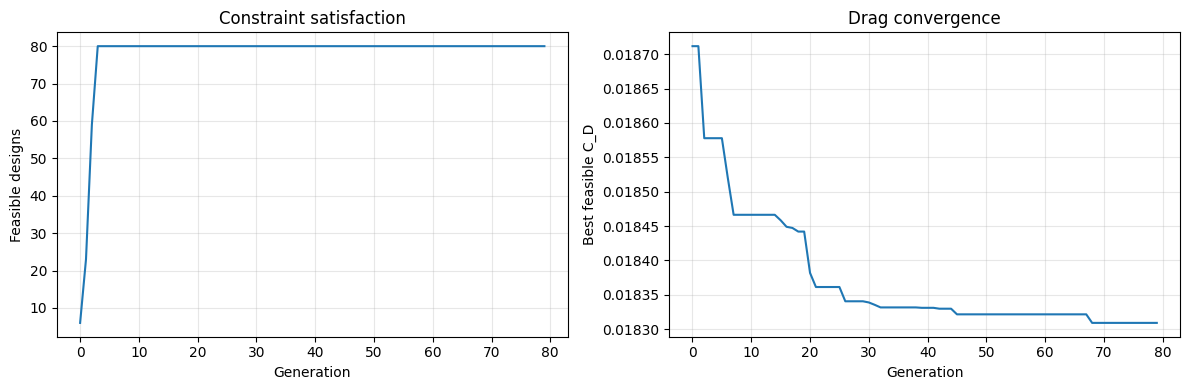

In [13]:
import matplotlib.pyplot as plt

history_generation = [item["generation"] for item in history]
history_feasible = [item["feasible_count"] for item in history]
history_best_drag = [item["best_drag"] for item in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_generation, history_feasible)
axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Feasible designs")
axes[0].set_title("Constraint satisfaction")
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_generation, history_best_drag)
axes[1].set_xlabel("Generation")
axes[1].set_ylabel("Best feasible C_D")
axes[1].set_title("Drag convergence")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

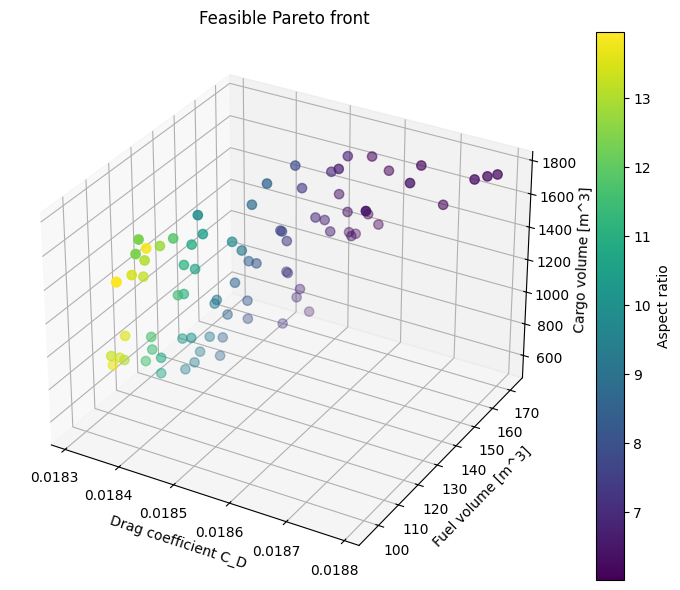

In [14]:
pareto_metrics = np.array([evaluate_aircraft(population[idx]) for idx in pareto_indices])

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    pareto_metrics[:, 0],
    pareto_metrics[:, 1],
    pareto_metrics[:, 2],
    c=pareto_metrics[:, 3],
    cmap="viridis",
    s=45,
)
ax.set_xlabel("Drag coefficient C_D")
ax.set_ylabel("Fuel volume [m^3]")
ax.set_zlabel("Cargo volume [m^3]")
ax.set_title("Feasible Pareto front")
fig.colorbar(scatter, ax=ax, label="Aspect ratio")
plt.tight_layout()
plt.show()